### imports

In [106]:
import torch
import numpy as np
import torch.nn as nn
import matplotlib.pyplot as plt

In [107]:
torch.manual_seed(42)
rng = np.random.default_rng(42)

### generate random number for X and Y

In [108]:
N = 30 # number of value
X = rng.random(N) * 10 - 5 # random number in [-5 , 5)
Y = 2 * X + 3 + rng.standard_normal(N)

In [109]:
X = X.reshape(N,1)
Y = Y.reshape(N,1)
Input = torch.from_numpy(X.astype(np.float32))
targets = torch.from_numpy(Y.astype(np.float32))

### create the linear regression model

In [110]:
model = nn.Linear(1,1)

### optimizer and loss function

In [111]:
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(),lr = 0.1)

### train loop

In [112]:
epoch = 30
losses = []
for i in range(epoch):
  # zero the prameter gradients
  optimizer.zero_grad()

  #forward pass
  output = model(Input)
  loss = criterion(output , targets)

  # keep the loss
  losses.append(loss.item())

  # Backward and optimizer
  loss.backward()
  optimizer.step()

  print(f'Epoch = {i} /{epoch}  , Loss : {loss.item() :.4f}')



Epoch = 0 /30  , Loss : 22.3234
Epoch = 1 /30  , Loss : 13.8153
Epoch = 2 /30  , Loss : 8.6557
Epoch = 3 /30  , Loss : 5.5223
Epoch = 4 /30  , Loss : 3.6165
Epoch = 5 /30  , Loss : 2.4555
Epoch = 6 /30  , Loss : 1.7471
Epoch = 7 /30  , Loss : 1.3140
Epoch = 8 /30  , Loss : 1.0488
Epoch = 9 /30  , Loss : 0.8861
Epoch = 10 /30  , Loss : 0.7861
Epoch = 11 /30  , Loss : 0.7245
Epoch = 12 /30  , Loss : 0.6864
Epoch = 13 /30  , Loss : 0.6629
Epoch = 14 /30  , Loss : 0.6483
Epoch = 15 /30  , Loss : 0.6392
Epoch = 16 /30  , Loss : 0.6336
Epoch = 17 /30  , Loss : 0.6301
Epoch = 18 /30  , Loss : 0.6279
Epoch = 19 /30  , Loss : 0.6265
Epoch = 20 /30  , Loss : 0.6256
Epoch = 21 /30  , Loss : 0.6251
Epoch = 22 /30  , Loss : 0.6247
Epoch = 23 /30  , Loss : 0.6245
Epoch = 24 /30  , Loss : 0.6244
Epoch = 25 /30  , Loss : 0.6243
Epoch = 26 /30  , Loss : 0.6242
Epoch = 27 /30  , Loss : 0.6242
Epoch = 28 /30  , Loss : 0.6242
Epoch = 29 /30  , Loss : 0.6242


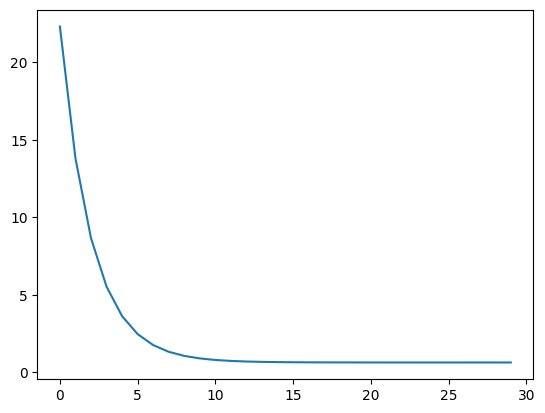

In [113]:
plt.plot(losses)

Learned Weight: 1.98 (True: 2.0), Learned Bias: 3.12 (True: 3.0)


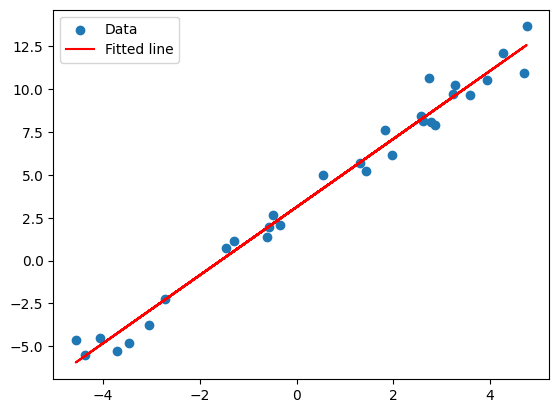

In [114]:
w, b = model.weight.item(), model.bias.item()
print(f"Learned Weight: {w:.2f} (True: 2.0), Learned Bias: {b:.2f} (True: 3.0)")

# رسم خط رگرسیون روی داده‌ها
plt.scatter(X, Y, label="Data")
plt.plot(X, model(Input).detach().numpy(), color="red", label="Fitted line")
plt.legend()
plt.show()